# Single Contact Discontinuity With Domain Extension

## Importing Libraries

In [95]:
import pandas as pd # Pandas
import numpy as np  # Numpy
import matplotlib.pyplot as plt # Matplotlibrarie

import math # math
import time # time

# for residual points generating
from pyDOE import lhs

# Import torch libraries
import torch
from torch import Tensor
import torch.autograd as autograd
import torch.optim as optim
import torch.nn as nn

# Libraries for saving datafiles
from numpy import asarray
from numpy import savetxt

## Set seed values for random number generation

In [96]:
## Random seed values:
torch.set_default_dtype(torch.float)
torch.manual_seed(789)
np.random.seed(789)

## Check GPU

In [97]:
# Empty the cache memory
torch.cuda.empty_cache()

# Save the device name of gpu
device=torch.cuda.get_device_name()
print("- Original device name:",device)

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("- Now device name is :- ",device)

- Original device name: NVIDIA GeForce RTX 3060 Laptop GPU
- Now device name is :-  cuda


## Generating data set for training the Model

In [98]:
x_data=np.linspace(0,1,100)[:,None] # Generate data x (position) from 0 to 1 (100 points)
t_data=np.linspace(0,2,100)[:,None] # Generate data t (time) from 0 to 2 sec (100 time step)

In [99]:
# Generate mesh grid for x and t coordinates
X,T=np.meshgrid(x_data,t_data)

# Flatten the grid structure to a matrix of size [100*100 X 2]
XT_Test=np.hstack((X.flatten()[:,None],T.flatten()[:,None]))

In [100]:
# Extended domain from -2.5 to 2.5 (1000 points)
x_data_extended=np.linspace(-2.5,2.5,1000)[:,None]

# Generate mesh grid for x and t coordinates
X_Extended,T=np.meshgrid(x_data_extended,t_data)

In [101]:
# Flatten the grid structure to a matrix of size [1000*100,2]
xt_train=np.hstack((X_Extended.flatten()[:,None],T.flatten()[:,None]))

## Initial Condition

In [102]:
# Initial Condition
## Initial discontinutiy is at x*=0.5.
Initial_xt=xt_train[0:1000,:]

Initial_xt_left=[]
Initial_xt_right=[]

for i in range(len(Initial_xt)):
    if Initial_xt[i,[0]]<=0.5:
        Initial_xt_left.append(Initial_xt[i])
    else:
        Initial_xt_right.append(Initial_xt[i])


#print(Initial_xt)
#print(Initial_xt_right)

# Initial dependent parameters
Initial_left_Rho=[1.4]*(len(Initial_xt_left))
Initial_left_U=[0.1]*(len(Initial_xt_left))
Initial_left_P=[1]*(len(Initial_xt_left))

Initial_right_Rho=[1]*(len(Initial_xt_right))
Initial_right_U=[0.1]*(len(Initial_xt_right))
Initial_right_P=[1]*(len(Initial_xt_right))


# Converting the list to the array.
Initial_xt_left=np.array(Initial_xt_left)
Initial_xt_right=np.array(Initial_xt_right)
#print(Initial_xt_right)

Initial_left_Rho=np.array(Initial_left_Rho)[:,None]
Initial_left_U=np.array(Initial_left_U)[:,None]
Initial_left_P=np.array(Initial_left_P)[:,None]

Initial_left_Rho_U_P=np.hstack((Initial_left_Rho,Initial_left_U,Initial_left_P))


Initial_right_Rho=np.array(Initial_right_Rho)[:,None]
Initial_right_U=np.array(Initial_right_U)[:,None]
Initial_right_P=np.array(Initial_right_P)[:,None]

## Horizontal stack the data
Initial_right_Rho_U_P=np.hstack((Initial_right_Rho,Initial_right_U,Initial_right_P))

## Boundary Condition

In [103]:
# Far field Condition
## Drichlet boundary condition is present at the boundarys same as the initial condition.
### Values at far field (extended region)

Boundary_left_far=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==-2.5]
Boundary_left_far=np.array(Boundary_left_far)

Boundary_right_far=[xt_train[i,:] for i in range(len(xt_train)) if xt_train[i,0]==2.5]
Boundary_right_far=np.array(Boundary_right_far)

Boundary_left_Rho_far=[1.4]*(len(Boundary_left_far))
Boundary_left_U_far=[0.1]*(len(Boundary_left_far))
Boundary_left_P_far=[1]*(len(Boundary_left_far))

Boundary_right_Rho_far=[1]*(len(Boundary_right_far))
Boundary_right_U_far=[0.1]*(len(Boundary_right_far))
Boundary_right_P_far=[1]*(len(Boundary_right_far))

Boundary_left_Rho_far=np.array(Boundary_left_Rho_far)[:,None]
Boundary_left_U_far=np.array(Boundary_left_U_far)[:,None]
Boundary_left_P_far=np.array(Boundary_left_P_far)[:,None]
Boundary_right_Rho_far=np.array(Boundary_right_Rho_far)[:,None]
Boundary_right_U_far=np.array(Boundary_right_U_far)[:,None]
Boundary_right_P_far=np.array(Boundary_right_P_far)[:,None]

# Horizontal stack the values.
Boundary_left_Rho_U_P_far=np.hstack((Boundary_left_Rho_far,Boundary_left_U_far,Boundary_left_P_far))
Boundary_right_Rho_U_P_far=np.hstack((Boundary_right_Rho_far,Boundary_right_U_far,Boundary_right_P_far))

In [104]:
# Conditions at boundaries
## Drichlet boundary condition is present at the boundarys same as the initial condition.
### Values at boundaries (origional region)

Boundary_left=[XT_Test[i,:] for i in range(len(XT_Test)) if XT_Test[i,0]==0]
Boundary_left=np.array(Boundary_left)

Boundary_right=[XT_Test[i,:] for i in range(len(XT_Test)) if XT_Test[i,0]==1]
Boundary_right=np.array(Boundary_right)


Boundary_left_Rho=[1.4]*(len(Boundary_left))
Boundary_left_U=[0.1]*(len(Boundary_left))
Boundary_left_P=[1]*(len(Boundary_left))

Boundary_right_Rho=[1]*(len(Boundary_right))
Boundary_right_U=[0.1]*(len(Boundary_right))
Boundary_right_P=[1]*(len(Boundary_right))


Boundary_left_Rho=np.array(Boundary_left_Rho)[:,None]
Boundary_left_U=np.array(Boundary_left_U)[:,None]
Boundary_left_P=np.array(Boundary_left_P)[:,None]
Boundary_right_Rho=np.array(Boundary_right_Rho)[:,None]
Boundary_right_U=np.array(Boundary_right_U)[:,None]
Boundary_right_P=np.array(Boundary_right_P)[:,None]

# Horizontal stack the values.
Boundary_left_Rho_U_P=np.hstack((Boundary_left_Rho,Boundary_left_U,Boundary_left_P))
Boundary_right_Rho_U_P=np.hstack((Boundary_right_Rho,Boundary_right_U,Boundary_right_P))


## Stacking the Values

In [105]:
Initial_condition=np.vstack((Initial_xt_left,Initial_xt_right))
Initial_condition_Rho_U_P=np.vstack((Initial_left_Rho_U_P,Initial_right_Rho_U_P))

Boundary_condition=np.vstack((Boundary_left,Boundary_right,Boundary_left_far,Boundary_right_far))
Boundary_condition_Rho_U_P=np.vstack((Boundary_left_Rho_U_P,Boundary_right_Rho_U_P,Boundary_left_Rho_U_P_far,Boundary_right_Rho_U_P_far))

In [106]:
# X_train=[Initial condition,
#          Boundary condition]
X_train=np.vstack((Initial_condition,Boundary_condition))


U_train=np.vstack((Initial_condition_Rho_U_P,Boundary_condition_Rho_U_P))


print("Shape of X_train: ",X_train.shape)
print("Shape of U_train: ",U_train.shape)

Shape of X_train:  (1400, 2)
Shape of U_train:  (1400, 3)


## Upper and Lower Limit for Feature Scaling

In [107]:
lb=xt_train[0] # Lower limit
ub=xt_train[-1] # Upper limit
print(lb,ub)

# lower and upper limit of modified region.
lb_L=xt_train[0]
ub_L=np.array([0, 2])

lb_M=np.array([0,0])
ub_M=np.array([1,2])

lb_R=np.array([1,0])
ub_R=np.array([2.5,2])
#print(lb_R)

[-2.5  0. ] [2.5 2. ]


## Generate Training Data

In [108]:
Nu=200 # Number of training points
Nf=1000 # number of residual points inside the original domain

# Number of residual points in the modified domain
Nf_L=300
Nf_R=200

# Generating the residual points
XT_f_train_M=lb_M+(ub_M-lb_M)*lhs(2,Nf)
XT_f_train_L=lb_L+(ub_L-lb_L)*lhs(2,Nf_L)
XT_f_train_R=lb_R+(ub_R-lb_R)*lhs(2,Nf_R)

In [109]:
# For random selection of training points
idx=np.random.choice(X_train.shape[0],Nu,replace=False)

#print(xt_train.shape)
XT_train=X_train[idx,:]
U_train=U_train[idx,:]

Shape of XT_trian: (200, 2)
Shape of U_trian: (200, 3)


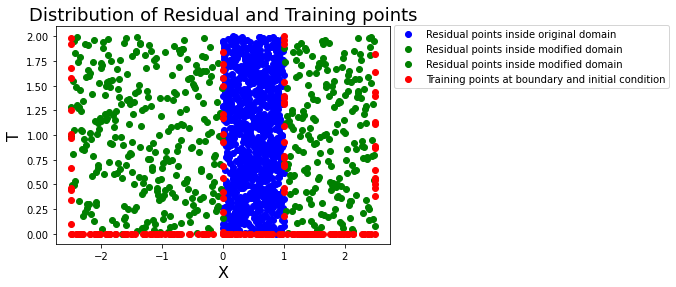

In [110]:
print("Shape of XT_trian:",XT_train.shape)
print("Shape of U_trian:",U_train.shape)

# Scatter plot of modified domain.
plt.scatter(XT_f_train_M[:,0],XT_f_train_M[:,1],color='b',label='Residual points inside original domain')
plt.scatter(XT_f_train_L[:,0],XT_f_train_L[:,1],color='g',label='Residual points inside modified domain')
plt.scatter(XT_f_train_R[:,0],XT_f_train_R[:,1],color='g',label='Residual points inside modified domain')
plt.scatter(XT_train[:,0],XT_train[:,1],color='r',label='Training points at boundary and initial condition')
plt.legend(loc=[1.01,0.718])
plt.xlabel("X",fontsize=16)
plt.ylabel("T",fontsize=16)
plt.title("Distribution of Residual and Training points",fontsize=18)
plt.show()

In [111]:
# Vertical stack all the XT_f_train points.

XT_f_train=np.vstack((XT_f_train_L,XT_f_train_M,XT_f_train_R))

In [112]:
#savetxt('XT_f_train_M',XT_f_train_M,delimiter=',')
#savetxt('XT_f_train_L',XT_f_train_L,delimiter=',')
#savetxt('XT_f_train_R',XT_f_train_R,delimiter=',')
#savetxt('XT_train',XT_train,delimiter=',')

## Convert the float to Torch

In [113]:
XT_train=torch.from_numpy(XT_train).float().to(device)
U_train=torch.from_numpy(U_train).float().to(device)
XT_f_train=torch.from_numpy(XT_f_train).float().to(device)

f_hat=torch.zeros(XT_f_train.shape[0],1).to(device)
XT_Test=torch.from_numpy(XT_Test).float().to(device)

In [114]:
print(XT_train.shape)
print(U_train.shape)
print(XT_f_train.shape)
print(f_hat.shape)

torch.Size([200, 2])
torch.Size([200, 3])
torch.Size([1500, 2])
torch.Size([1500, 1])


## PINNs

In [115]:
class Single_Discontinuity(nn.Module):
    
    def __init__(self,layers):
        
        # Inherentance: taking the function form nn.Module
        super().__init__()
        
        # Define the activation function
        self.activation=nn.Tanh()
        
        # Define the Loss function as Mean square Loss function
        self.Loss_function=nn.MSELoss(reduction='mean')
        
        # Generating the ModuleList
        self.linears=nn.ModuleList([nn.Linear(layers[i],layers[i+1]) for i in range(len(layers)-1)])
        
        # Iteration
        self.iter=0
        
        # Defining the Xavier normal for weight and zero as bias
        for i in range(len(layers)-1):
            nn.init.xavier_normal_(self.linears[i].weight.data,gain=5/3)
            nn.init.zeros_(self.linears[i].bias.data)
    
    # Forward Pass function
    def forward(self,X):
        
        # Check whether the X data is Tensor or not
        if torch.is_tensor(X)!=True:
            X=torch.from_numpy(X)
            
        # Converting the Boundary values (min,max)
        L_b=torch.from_numpy(lb).float().to(device)
        U_b=torch.from_numpy(ub).float().to(device)
        
        # Feature Scale
        X=(X-L_b)/(U_b-L_b)
        
        a=X.float()
        
        Rho_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        U_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        P_Pred=torch.cat((a[:,[0]],a[:,[1]]),1)
        
        # Forward Pass loop upto the second last layer 
        for i in range(len(layers)-2):
            z1=self.linears[i](Rho_Pred)
            z2=self.linears[i](U_Pred)
            z3=self.linears[i](P_Pred)
            
            Rho_Pred=self.activation(z1)
            U_Pred=self.activation(z2)
            P_Pred=self.activation(z3)
            
        # Pass the the data to the last layer
        Rho_Pred=self.linears[-1](Rho_Pred)
        U_Pred=self.linears[-1](U_Pred)
        P_Pred=self.linears[-1](P_Pred)
        
        # a=[Rho, U, P]
        a=torch.cat((Rho_Pred,U_Pred,P_Pred),1)
        
        return a
    
    def LossBC(self,X,Y):
        
        # Forward Pass the X data for boundary and Initial Values
        Pred_val=self.forward(X)
        
        PRED_RHO=Pred_val[:,[0]]
        PRED_U=Pred_val[:,[1]]
        PRED_P=Pred_val[:,[2]]
        
        # Calculating the MSE Loss of predicted data
        Loss_Rho=self.Loss_function(PRED_RHO,Y[:,[0]])
        
        Loss_U=self.Loss_function(PRED_U,Y[:,[1]])
        Loss_P=self.Loss_function(PRED_P,Y[:,[2]])
        
        # total Boundary and Initial Loss
        Loss_BC=Loss_Rho+Loss_U+Loss_P
        
        return Loss_BC
    
    def LossPDE(self,xy_to_train_f):
        
        # Gamma for air
        gamma=1.4
        
        g=xy_to_train_f.clone()
        
        g.requires_grad=True
        
        # Forward Pass the the data xy_to_train_f
        RHO_U_P=self.forward(g)
        
        RHO=RHO_U_P[:,[0]]
        U=RHO_U_P[:,[1]]
        P=RHO_U_P[:,[2]]
        
        # Calculating the gradient of the calculated RHO
        RHO_xt=autograd.grad(RHO,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        RHO_x=RHO_xt[:,[0]]
        RHO_t=RHO_xt[:,[1]]
        
        # Calculating the gradient of the calculated U
        U_xt=autograd.grad(U,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        U_x=U_xt[:,[0]]
        U_t=U_xt[:,[1]]
        
        # Calculating the gradient of the calculated P
        P_xt=autograd.grad(P,g,torch.ones([xy_to_train_f.shape[0],1]).to(device), retain_graph=True,create_graph=True)[0]
        P_x=P_xt[:,[0]]
        P_t=P_xt[:,[1]]
        
        # Three eqution, Conservation of mass, momentum and energy
        F1=RHO_t + U*(RHO_x) + RHO*(U_x)
        F2=RHO*(U_t + U*(U_x)) + P_x
        F3=P_t + gamma*P*(U_x) + U*(P_x)
        
        # Equation 
        # Entroypy calculation
        
        
        
        # MSE Loss function Calculation 
        LossF1=self.Loss_function(F1,f_hat)
        LossF2=self.Loss_function(F2,f_hat)
        LossF3=self.Loss_function(F3,f_hat)
        #LossF4=self.Loss_function(F4,f_hat)
        
        # Total PDE LOSS
        LossPDE=LossF1+LossF2+LossF3
        
        return LossPDE
    
    def Loss(self,X,Y,xy_to_train_f):
        
        # Calling the Boundary Loss function
        Loss1=self.LossBC(X,Y)
        
        # Calling the PDE Loss function
        Loss2=self.LossPDE(xy_to_train_f)
        
        # Total MSE LOSS--> Sum of the PDE_LOSS + BC_LOSS
        Total_Loss_W=Loss1*10 + Loss2*0.1  # With dynamic weights
        
        Total_Loss=Loss1 + Loss2
        
        # Saving the Data
        #file1=open('BC_LOSS.txt','a')
        #file1.write(str(Loss1.item())+'\n')
        #file1.close()
        
        #file1=open('PDE_LOSS.txt','a')
        #file1.write(str(Loss2.item())+'\n')
        #file1.close()
        
        #file3=open('TOTAL_LOSS_W_PINNs.txt','a')
        #file3.write(str(Total_Loss_W.item())+'\n')
        #file3.close()
        
        #file4=open('TOTAL_LOSS.txt','a')
        #file4.write(str(Total_Loss.item())+'\n')
        #file4.close()
        
        return Total_Loss
    
    def closure(self):
        
        # Initial taking the gradient as zero
        optimizer.zero_grad()
        
        # Calling the Loss function
        Loss=self.Loss(XT_train,U_train,XT_f_train)
        
        
        # Backprop
        Loss.backward()
        
        # Iteration +=1
        self.iter+=1
        
        # Print the Loss at every 100 iteration
        if self.iter%100==0:
            print(Loss)
            
        return Loss
    
    def Test(self,Test_data):
        
        # Forward Pass the Test Data
        Result_Pred=self.forward(Test_data)
        
        # Taking the Results to the cpu from the gpu
        Result_Pred=Result_Pred.detach().cpu().numpy()
        
        Density_Pred=Result_Pred[:,[0]]
        Velocity_Pred=Result_Pred[:,[1]]
        Pressure_Pred=Result_Pred[:,[2]]
        
        return [Density_Pred,Velocity_Pred,Pressure_Pred]
        

In [116]:
layers=[2,40,40,3] # No of neurons in each layer

# Object of the the class
SD=Single_Discontinuity(layers)

# Passing the object to the device
SD.to(device)

params=list(SD.parameters())

# Optimization methods
optimizer=optim.LBFGS(SD.parameters(),lr=0.1,max_iter=10000)

# Training time for the optimization
start_time1=time.time()
optimizer.step(SD.closure)
Training_time1=time.time()-start_time1

print("Training Time:- ", Training_time1)

tensor(0.0093, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0057, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0030, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0024, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0013, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0008, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0005, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0003, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0002, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0002, device='cuda:0', grad_fn=<AddBackward0>)
tensor(0.0001, device='cuda:0', grad_fn=<AddBackward0>)
tensor(8.2932e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(5.7984e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(4.0689e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(3.3961e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(2.7815e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(2.4076e-05, device='cuda:0', grad_fn=<AddBackward0>)
tensor(1.9725e-05, devic

---
---

## Prediction

- ###  At time t=0

In [117]:
Test_data1=XT_Test[0:100,:]
#print(Test_data1)
[RHO_PRED_t0,U_PRED_t0,P_PRED_t0]=SD.Test(Test_data1)

In [118]:
Test_data1=Test_data1.detach().cpu().numpy()

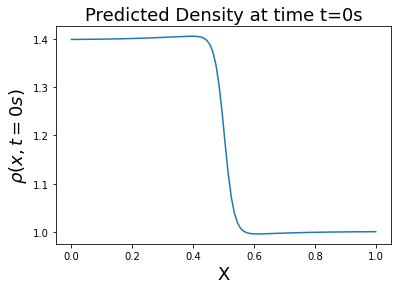

In [119]:
plt.plot(Test_data1[:,[0]],RHO_PRED_t0)
plt.xlabel("X",fontsize=18)
plt.ylabel(r"$\rho(x,t=0s)$",fontsize=18)
plt.title("Predicted Density at time t=0s",fontsize=18)
plt.show()

- ### t=0.5

In [120]:
Test_data05=XT_Test[2500:2600,:]
#print(Test_data05)
[RHO_PRED_t05,U_PRED_t05,P_PRED_t05]=SD.Test(Test_data05)

In [121]:
Test_data05=Test_data05.detach().cpu().numpy()

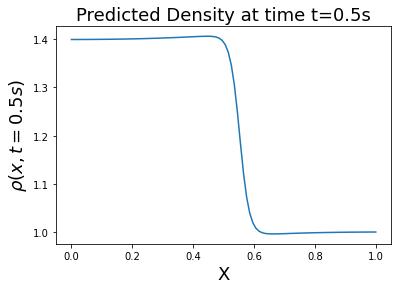

In [122]:
plt.plot(Test_data05[:,[0]],RHO_PRED_t05)
plt.xlabel("X",fontsize=18)
plt.ylabel(r"$\rho(x,t=0.5s)$",fontsize=18)
plt.title("Predicted Density at time t=0.5s",fontsize=18)
plt.show()

- ## t=1

In [123]:
Test_data1=XT_Test[5000:5100,:]
#print(Test_data1)
[RHO_PRED_t1,U_PRED_t1,P_PRED_t1]=SD.Test(Test_data1)

In [124]:
Test_data1=Test_data1.detach().cpu().numpy()

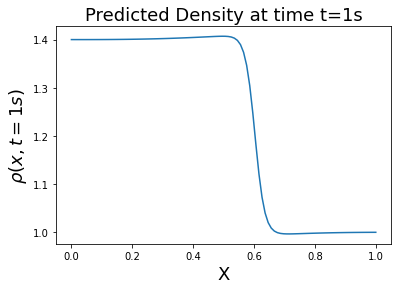

In [125]:
plt.plot(Test_data1[:,[0]],RHO_PRED_t1)
plt.xlabel("X",fontsize=18)
plt.ylabel(r"$\rho(x,t=1s)$",fontsize=18)
plt.title("Predicted Density at time t=1s",fontsize=18)
plt.show()

- ## t=2s

In [126]:
Test_data2=XT_Test[9900:,:]
#print(Test_data1)
[RHO_PRED_t2,U_PRED_t2,P_PRED_t2]=SD.Test(Test_data2)

In [127]:
Test_data2=Test_data2.detach().cpu().numpy()

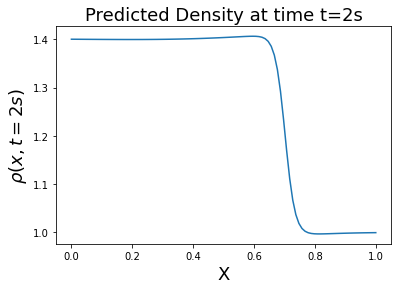

In [128]:
plt.plot(Test_data2[:,[0]],RHO_PRED_t2)
plt.xlabel("X",fontsize=18)
plt.ylabel(r"$\rho(x,t=2s)$",fontsize=18)
plt.title("Predicted Density at time t=2s",fontsize=18)
plt.show()

## Exact solution

In [129]:
# Exact Solution at t=0s

Exact_t0=XT_Test[0:100,:]
#print(Exact_t0)
#print(Initial_xt)
Exact_xt0_left=Exact_t0[:50,:]
Exact_xt0_right=Exact_t0[50:,:]
Exact_t0_left_Rho=[1.4]*(len(Exact_xt0_left))
Exact_t0_right_Rho=[1]*(len(Exact_xt0_right))
RHO_LEFT_t0=np.hstack((Exact_t0_left_Rho,Exact_t0_right_Rho))
print(RHO_LEFT_t0.shape)

##-----------------##---------------##------------------##---------------##

# Exact solution at t=1s
Exact_t1=XT_Test[5000:5100,:]
#print(Exact_t1)
Exact_xt1_left=Exact_t1[:61,:]
Exact_xt1_right=Exact_t1[62:,:]
Exact_t1_left_Rho=[1.4]*(len(Exact_xt1_left))
Exact_t1_right_Rho=[1]*(len(Exact_xt1_right))
#print(Exact_xt1_left)
RHO_LEFT_t1=np.hstack((Exact_t1_left_Rho,Exact_t1_right_Rho))


##-----------------##---------------##------------------##---------------##

# Exact solution at t=2s

Exact_t2=(XT_Test[9900:,:])
#print(Exact_t2)
Exact_xt2_left=Exact_t2[:70,:]
Exact_xt2_right=Exact_t2[70:,:]
#print(Exact_xt2_right)
Exact_t2_left_Rho=[1.4]*(len(Exact_xt2_left))
Exact_t2_right_Rho=[1]*(len(Exact_xt2_right))
RHO_LEFT_t2=np.hstack((Exact_t2_left_Rho,Exact_t2_right_Rho))

#savetxt('Exact_t2',Exact_t2,delimiter=',')
#savetxt('RHO_LEFT_t2',RHO_LEFT_t2,delimiter=',')

(100,)


In [130]:
Exact_t2=Exact_t2.detach().cpu().numpy()

---
---

## Comparision plot

[]

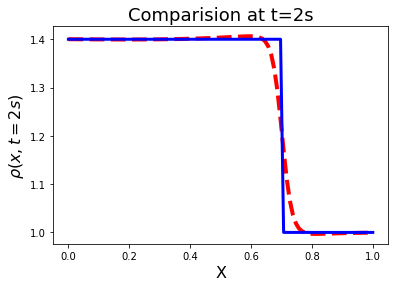

In [131]:
plt.plot(Test_data2[:,[0]],RHO_PRED_t2,color='r',linestyle='--',
         linewidth=4, label='PINNs')
plt.plot(Exact_t2[:,[0]],RHO_LEFT_t2,color='b',linewidth=3,label='Exact')
plt.xlabel("X",fontsize=16)
plt.ylabel(r"$\rho(x,t=2s)$",fontsize=16)
plt.title("Comparision at t=2s",fontsize=18)
plt.plot()


#savetxt('Test_data2',Test_data2[:,[0]],delimiter=',')
#savetxt('RHO_PRED_t2',RHO_PRED_t2,delimiter=',')
#savetxt('RHO_LEFT_t2',RHO_LEFT_t2,delimiter=',')

---
---

## Relative Error

$$\frac{||\rho_{Exact}-\rho_{Predicted}||_{L2}}{||\rho_{Exact}||_{L2}}$$

In [132]:
# Relative error for density

error=0
sum_pred=0
for i in range(len(RHO_LEFT_t2)):
    error+=((RHO_LEFT_t2[i]-RHO_PRED_t2[i])**2)
    sum_pred+=(RHO_LEFT_t2[i])**2


error_root=error**0.5/(sum_pred**0.5)
print("\n The Relative Error for density: ",error_root[-1])


 The Relative Error for density:  0.02351089


---
---